# 04 · Análise de sensibilidade de Morris

Primeiro passo da Fase B: identificar quais parâmetros entram na calibração.

- **Modelo:** configuração validada de Battisti & Sentelhas (2019, v2), com MG por faixa de latitude.
- **Parâmetros (15):** 13 coeficientes de cultivar e ecótipo (faixas: envoltória da literatura brasileira e dos MG 5–10 do DSSAT), fator da água disponível (0,6–1,4) e profundidade de raiz (40–120 cm, escalando o SRGF da Tabela S2).
- **Desenho:** 10 trajetórias, 4 níveis (SALib), 160 conjuntos.
- **Ambientes:** 2 pontos por zona do artigo (maior área de soja), solo dominante do MapBiomas, semeaduras de 15/out, 15/nov e 15/dez, 33 safras (1980–2013).
- **Saídas:** produtividade atingível média (Yw), CV interanual, dias até R1 e até R7.

Em cada ambiente, μ* é normalizado pelo maior μ* daquele ambiente (0–1), para que zonas com produtividades diferentes pesem igual.

In [1]:
import sys, warnings
from pathlib import Path
warnings.filterwarnings("ignore")
RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(RAIZ / "src"))
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from SALib.analyze import morris as analise_morris
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})
import morris as mo
DIR = RAIZ / "resultados" / "morris"
X = np.load(DIR / "amostras.npy")
s = pd.read_csv(DIR / "saidas.csv")
print(f"{len(s)} rodadas | com erro: {s['erro'].notna().sum() if 'erro' in s else 0}")
SAIDAS = {"yw": "Produtividade atingível", "cv": "CV interanual", "r1": "Dias até R1", "r7": "Dias até R7"}

9600 rodadas | com erro: 0


/Users/coted-sh/Python/DSSAT/calibracao_mg/.venv/lib/python3.11/site-packages/DSSATTools/__init__.py:105: DeprecationWarning: DSSATTools version 3.0.0 is a major upgrade and will not be backwards compatible with previous versions. If you are running code that was developed  using a previous DSSATTools version, then install DSSATTools version 2.1.6
  warnings.warn(


In [2]:
linhas = []
for (lon, lat, zona, sem), g in s.groupby(["lon", "lat", "zona", "semeadura"]):
    g = g.set_index("amostra").reindex(range(len(X)))
    for y in SAIDAS:
        Y = g[y].values
        if np.isnan(Y).any():
            continue
        a = analise_morris.analyze(mo.PROBLEMA, X, Y, num_levels=4, seed=1)
        mu = np.array(a["mu_star"]); sig = np.array(a["sigma"])
        for nome, m, sg in zip(mo.PROBLEMA["names"], mu, sig):
            linhas.append(dict(lon=lon, lat=lat, zona=zona, semeadura=sem, saida=y, parametro=nome,
                               mu_star=m, sigma=sg, mu_norm=m / mu.max() if mu.max() > 0 else 0))
ind = pd.DataFrame(linhas)
ind.to_csv(DIR / "indices_morris.csv", index=False)
rank = ind.groupby(["saida", "parametro"]).mu_norm.mean().unstack("saida")[list(SAIDAS)].sort_values("yw", ascending=False)
rank.round(2)

saida,yw,cv,r1,r7
parametro,,,,
fator_ad,0.74,0.97,0.06,0.03
csdl,0.72,0.51,0.79,1.00
prof_raiz,0.48,0.75,0.05,0.02
lfmax,0.42,0.09,0.00,0.00
em-fl,0.41,0.30,0.93,0.39
fl-sd,0.41,0.29,0.00,0.30
sfdur,0.37,0.29,0.00,0.00
sd-pm,0.27,0.16,0.00,0.36
ppsen,0.24,0.30,0.44,0.45


## Importância relativa no Brasil (média dos ambientes)

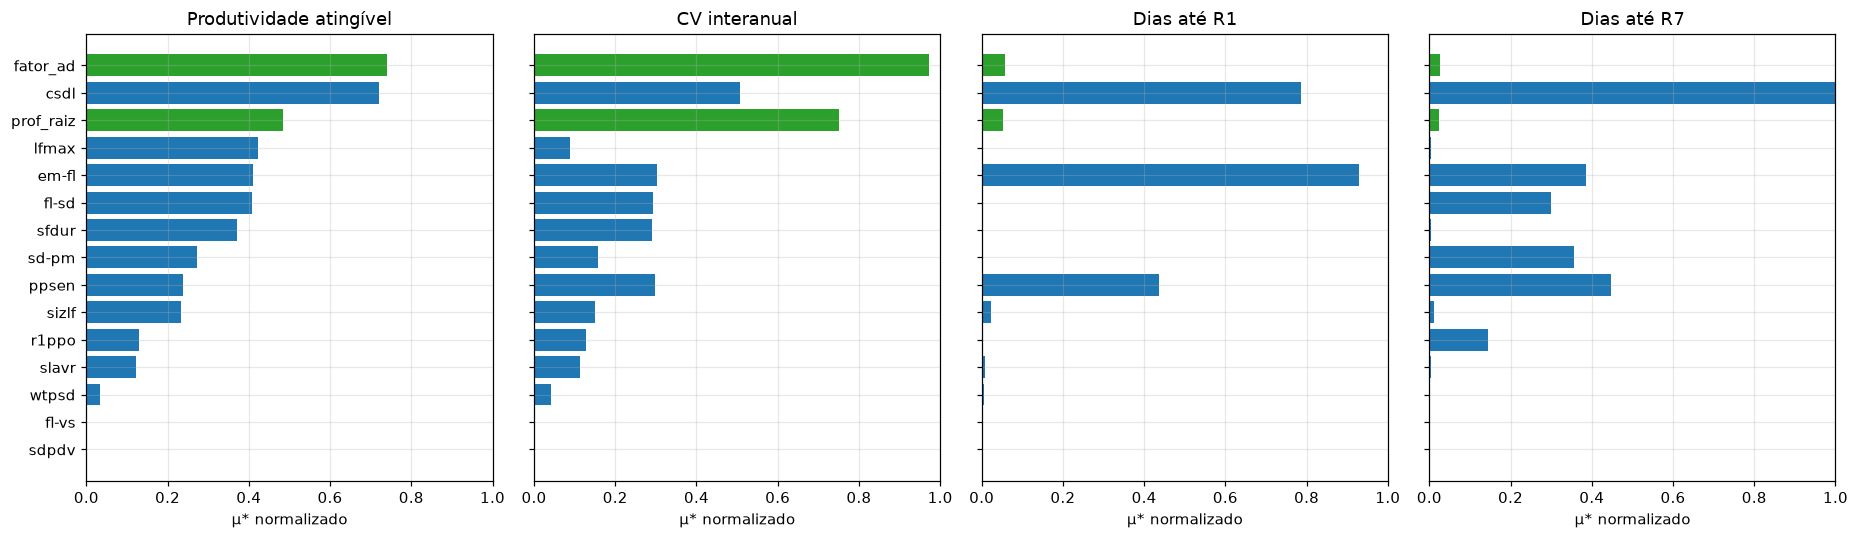

In [3]:
fig, axs = plt.subplots(1, 4, figsize=(17, 5), sharey=True)
ordem = rank.index[::-1]
for ax, (y, tit) in zip(axs, SAIDAS.items()):
    ax.barh(ordem, rank.loc[ordem, y], color=["tab:green" if p in ("fator_ad", "prof_raiz") else "tab:blue" for p in ordem])
    ax.set_title(tit); ax.set_xlim(0, 1); ax.set_xlabel("μ* normalizado")
fig.tight_layout(); fig.savefig(DIR / "ranking_morris.png", bbox_inches="tight")

## Produtividade atingível por zona

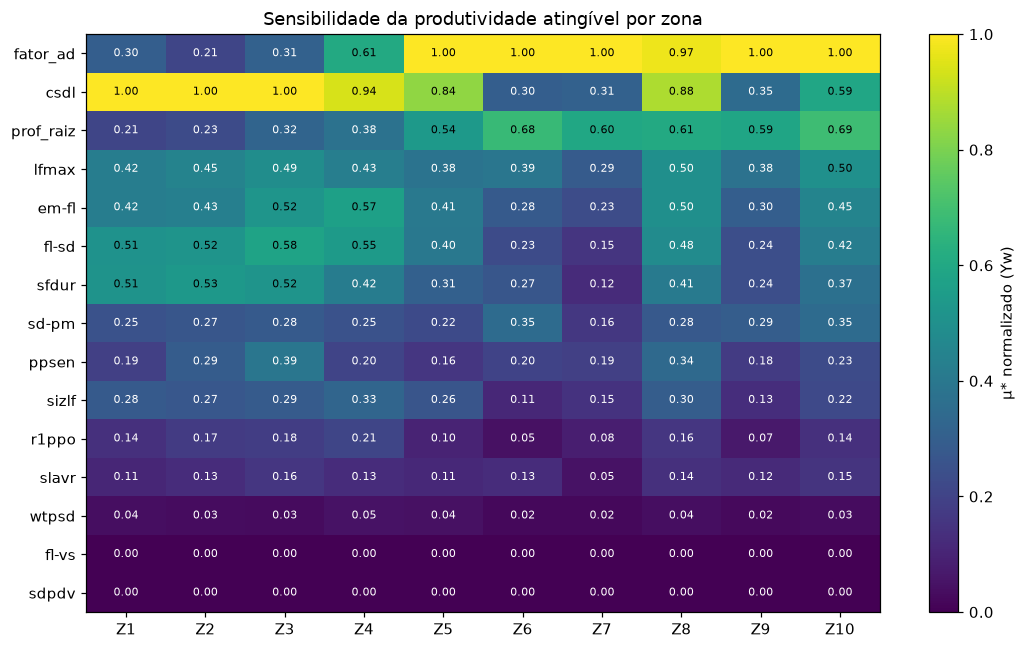

In [4]:
z = ind[ind.saida == "yw"].groupby(["parametro", "zona"]).mu_norm.mean().unstack("zona").loc[rank.index]
fig, ax = plt.subplots(figsize=(10, 6))
im = ax.imshow(z.values, cmap="viridis", vmin=0, vmax=1, aspect="auto")
ax.set_yticks(range(len(z)), z.index); ax.set_xticks(range(z.shape[1]), [f"Z{int(c)}" for c in z.columns]); ax.grid(False)
for (i, j), v in np.ndenumerate(z.values): ax.text(j, i, f"{v:.2f}", ha="center", va="center", fontsize=7, color="w" if v < .5 else "k")
plt.colorbar(im, label="μ* normalizado (Yw)"); ax.set_title("Sensibilidade da produtividade atingível por zona")
fig.tight_layout(); fig.savefig(DIR / "morris_yw_zonas.png", bbox_inches="tight")

## μ* × σ: efeito linear ou interações

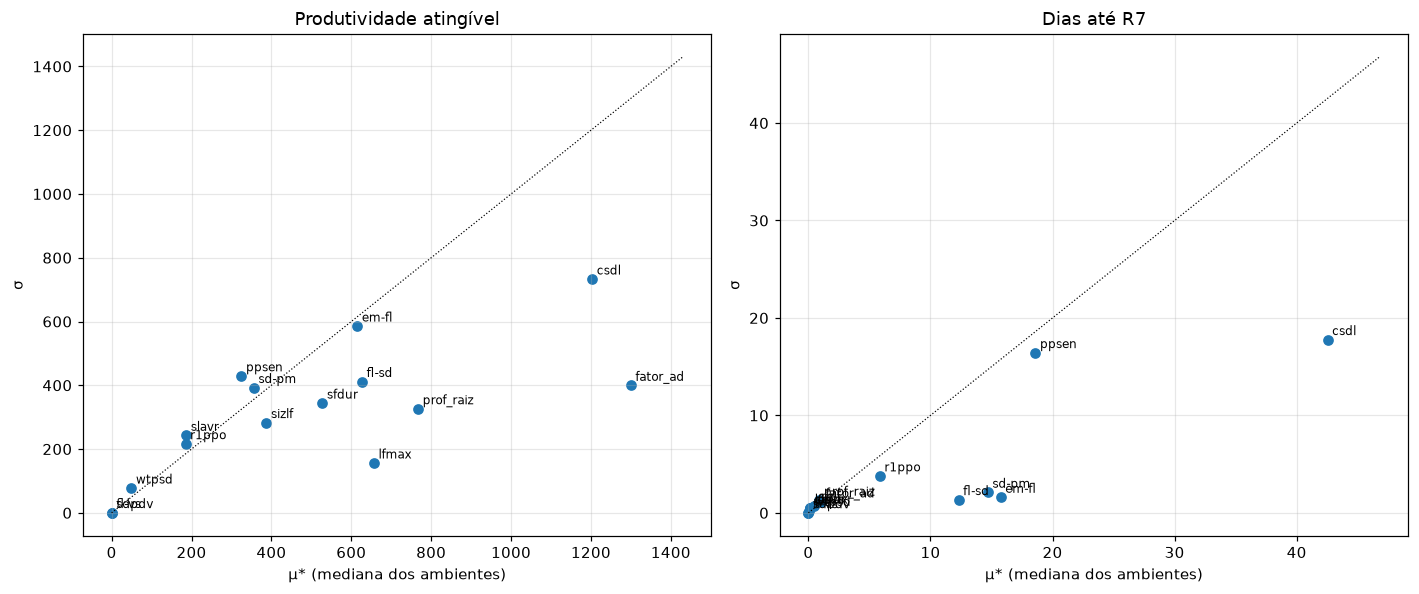

In [5]:
fig, axs = plt.subplots(1, 2, figsize=(13, 5.5))
for ax, y in zip(axs, ["yw", "r7"]):
    m = ind[ind.saida == y].groupby("parametro")[["mu_star", "sigma"]].median()
    ax.scatter(m.mu_star, m.sigma, color="tab:blue")
    for p, r in m.iterrows(): ax.annotate(p, (r.mu_star, r.sigma), fontsize=8, xytext=(3, 3), textcoords="offset points")
    lim = max(m.mu_star.max(), m.sigma.max()) * 1.1; ax.plot([0, lim], [0, lim], "k:", lw=0.8)
    ax.set_xlabel("μ* (mediana dos ambientes)"); ax.set_ylabel("σ"); ax.set_title(SAIDAS[y])
fig.tight_layout(); fig.savefig(DIR / "morris_mu_sigma.png", bbox_inches="tight")

## Seleção para a calibração

Critério: parâmetro com μ* normalizado ≥ 0,1 em alguma das saídas (na média do Brasil ou em ao menos 3 zonas). Os demais ficam fixos nos valores de Battisti & Sentelhas (2019).

In [6]:
zonas_yw = (ind[ind.saida == "yw"].groupby(["parametro", "zona"]).mu_norm.mean() >= 0.1).groupby("parametro").sum()
sel = pd.DataFrame({"max_brasil": rank.max(axis=1), "zonas_yw_ge_0.1": zonas_yw})
sel["selecionado"] = (sel.max_brasil >= 0.1) | (sel["zonas_yw_ge_0.1"] >= 3)
sel.sort_values("max_brasil", ascending=False).round(2)

,max_brasil,zonas_yw_ge_0.1,selecionado
parametro,,,
csdl,1.00,10,True
fator_ad,0.97,10,True
em-fl,0.93,10,True
prof_raiz,0.75,10,True
ppsen,0.45,10,True
lfmax,0.42,10,True
fl-sd,0.41,10,True
sfdur,0.37,10,True
sd-pm,0.36,10,True


## Leitura

**Ranking (μ* normalizado, média dos 60 ambientes):**

| Parâmetro | Yw | CV | R1 | R7 | σ/μ* (Yw) |
|---|---|---|---|---|---|
| fator_ad | 0,74 | 0,97 | 0,06 | 0,03 | 0,31 |
| CSDL | 0,72 | 0,51 | 0,79 | **1,00** | 0,61 |
| prof_raiz | 0,48 | 0,75 | 0,05 | 0,02 | 0,43 |
| LFMAX | 0,42 | 0,09 | 0 | 0 | 0,24 |
| EM-FL | 0,41 | 0,30 | **0,93** | 0,39 | 0,95 |
| FL-SD | 0,41 | 0,29 | 0 | 0,30 | 0,66 |
| SFDUR | 0,37 | 0,29 | 0 | 0 | 0,65 |
| SD-PM | 0,27 | 0,16 | 0 | 0,36 | 1,10 |
| PPSEN | 0,24 | 0,30 | 0,44 | 0,45 | 1,32 |
| SIZLF | 0,23 | 0,15 | 0,02 | 0,01 | 0,73 |
| R1PPO | 0,13 | 0,13 | 0 | 0,14 | 1,17 |
| SLAVR | 0,12 | 0,11 | 0,01 | 0 | 1,30 |
| WTPSD | 0,03 | 0,04 | 0 | 0 | 1,57 |
| FL-VS, SDPDV | 0 | 0 | 0 | 0 | — |

- **Duas regiões de comportamento.** Nas zonas úmidas do Norte e do Centro-Oeste (1–3), a produtividade é controlada pela fenologia (CSDL = 1,00) e pelo crescimento (LFMAX, FL-SD, SFDUR); o solo pesa 0,2–0,3. Nas zonas secas e no Sul (5–10), o fator de água disponível domina (1,00) e a profundidade de raiz vem em seguida (0,54–0,69). Os parâmetros de solo só são identificáveis onde a água limita a produção.
- **CSDL é o coeficiente mais importante** para a fenologia (R7 = 1,00, R1 = 0,79) e o segundo para a produtividade. É o que mais muda com o MG, o que confirma a abordagem θ(MG).
- **Interações fortes** (σ/μ* ≈ 1 ou mais) em EM-FL, SD-PM, PPSEN e R1PPO: o efeito de cada um depende dos demais. Por isso a calibração precisa ser conjunta (bayesiana), e não um parâmetro por vez.
- **Efeito nulo** (verificado rodando os extremos): SDPDV e FL-VS mudam Yw em menos de 1 kg/ha, e WTPSD em 0,7%. Nesta configuração o número e o tamanho dos grãos não limitam a produção, que é regulada pela oferta de assimilados.

**Seleção para a calibração (10 parâmetros):**
- fenologia: CSDL, PPSEN, EM-FL, FL-SD, SD-PM;
- crescimento: LFMAX, SFDUR, SIZLF;
- solo: fator_ad, prof_raiz.

Ficam fixos nos valores de Battisti & Sentelhas (2019): SLAVR, R1PPO, WTPSD, FL-VS e SDPDV.

**Riscos de equifinalidade:** fator_ad × prof_raiz (os dois controlam a água disponível para a planta) e LFMAX × SFDUR (os dois controlam a produtividade potencial). Na calibração, os dados de fenologia restringem os cinco coeficientes fenológicos, e a produtividade (experimentos e IBGE) restringe os de crescimento e de solo.